# Videos with `robotdesigner`: record, save, show

Render a rollout of the reach task and turn it into an MP4 or GIF, then save it or show it right here.
Recording is Gymnasium-style: the live state is rendered while the rollout runs. See `docs/viz.md` for the full guide.

Install first: `pip install -e ".[env,viz]"` (Pillow writes GIFs, imageio-ffmpeg writes MP4s).
Rendering needs an OpenGL context; on a headless Linux machine MuJoCo needs EGL, set **before mujoco is imported**.

In [1]:
import io
import os
import sys

# Headless Linux (no DISPLAY, e.g. a cluster node): use EGL. This must happen before mujoco is imported;
# if mujoco was already imported in this kernel, set MUJOCO_GL=egl in the environment and restart the kernel.
if sys.platform == "linux" and not os.environ.get("DISPLAY"):
    os.environ.setdefault("MUJOCO_GL", "egl")

import numpy as np
import torch
from IPython.display import Image as IPImage
from IPython.display import display
from PIL import Image
from tensordict import TensorDict

from robotdesigner.config import (
    ControlConfig, EnvConfig, FixedBox, FixedGains, MujocoOptions, Pose, SimConfig, chain,
)
from robotdesigner.config import kinematics as kin
from robotdesigner import make_env
from robotdesigner.tasks.native import reach_task
from robotdesigner.viz import VIEWS, FrameRecorder, annotate, auto_camera, record_rollout, tile, tile_clips


def show(image, quality=90):
    """Show an RGB array as one small JPEG (keeps the notebook file small)."""
    buf = io.BytesIO()
    Image.fromarray(image).save(buf, format="JPEG", quality=quality)
    display(IPImage(data=buf.getvalue(), format="jpeg"))

## 1. An environment

The same reach task as in `reach_cpu.ipynb`, with `n` and the arm length as arguments so that section 6 can compare
embodiments.

In [2]:
def make_config(n=3, length=0.9, num_envs=4, horizon=100):
    arm = chain(
        n=n, axes=("zy" * n)[:n], total_length=length, total_mass=3.0, radius=0.03,
        damping=0.5, armature=0.01, frictionloss=0.0, effort_limit=50.0, range=(-2.5, 2.5),
        base_pose=Pose((0.0, 0.0, 0.5), (1.0, 0.0, 0.0, 0.0)),
    )
    return EnvConfig(
        robot=arm,
        control=ControlConfig("joint_pos_abs", FixedGains(kp=60.0, kd=6.0), action_scale=None),
        task=reach_task(
            horizon=horizon, success_tolerance=0.02,
            target_region=FixedBox(low=(0.2, -0.3, -0.2), high=(0.6, 0.3, 0.2)),
            reset_noise=0.0, terminate_on_success=False,
        ),
        sim=SimConfig(backend="mujoco", num_envs=num_envs, device="cpu", dt=0.002, integrator="euler",
                      control_freq=50, seed=0, scene="plain_floor"),
        backend_options=MujocoOptions(self_collision=False),
    )


env = make_env(make_config(num_envs=4))
env.reset()
env.batch_size, env.cfg.sim.control_freq

(torch.Size([4]), 50.0)

## 2. One frame

`env.render()` returns the live state of one env as a `uint8 (H, W, 3)` array (like Gymnasium's `rgb_array`).
A frame shows the whole MuJoCo scene plus overlays drawn from task state: the target and the target region (a blue
wireframe box). Rendering never changes the simulation.

(240, 320, 3) uint8


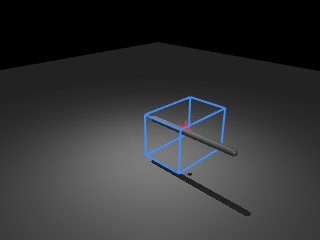

In [3]:
frame = env.render(size=(240, 320))          # env 0, default "iso" view
print(frame.shape, frame.dtype)
show(frame)

The target is red until the end effector is within `success_tolerance` of it, then green. Here the target is put on the
end effector (left) and 0.25 m away from it (right) through the reset.

target on the end effector: success = True


target 0.25 m away: success = False


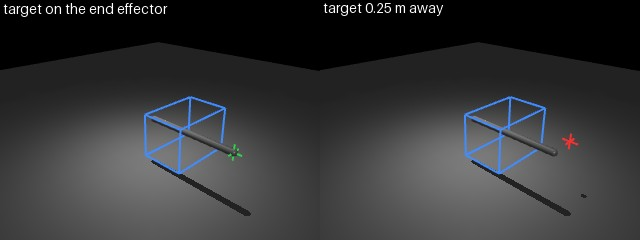

In [4]:
ee = env.reset()["task", "ee_pos"]                                    # end effector at the home pose, (N, 3)
frames = []
for label, target in [("target on the end effector", ee), ("target 0.25 m away", ee + torch.tensor([0.0, 0.25, 0.0]))]:
    td = env.reset(TensorDict({"target": target.clone()}, batch_size=env.batch_size))
    print(f"{label}: success = {bool(td['success'][0])}")
    frames.append(annotate(env.render(size=(240, 320)), label))
show(np.hstack(frames))

## 3. Record a rollout and see it

Any `policy(td) -> td` works, for example a trained one. Here a small scripted policy takes damped least-squares steps
on the arm's Jacobian (from the numpy kinematics oracle) towards the target and integrates them into the joint targets.
A small gain keeps it smooth.

In [5]:
def make_reach_policy(env, gain=0.15, max_step=0.05, damping=0.05):
    arm, rng = env.cfg.robot, env.interface.joint_range
    scale, offset = (rng[:, 1] - rng[:, 0]) / 2.0, (rng[:, 1] + rng[:, 0]) / 2.0   # joint_pos_abs: ctrl = a * scale + offset
    state = {"q_cmd": None}

    def policy(td):
        q = td["proprio", "qpos"].double().numpy()                                   # (N, n)
        if state["q_cmd"] is None:
            state["q_cmd"] = q.copy()
        fresh = (td["episode_step"].reshape(-1) == 0).numpy()                        # rows that were just reset
        state["q_cmd"][fresh] = q[fresh]
        err = (td["task", "target_pos"] - td["task", "ee_pos"]).double().numpy()     # (N, 3)
        err = np.clip(err, -max_step, max_step)
        base = kin.forward_ee_batch(arm, q)
        J = np.stack([(kin.forward_ee_batch(arm, q + 1e-4 * np.eye(arm.n)[j]) - base) / 1e-4
                      for j in range(arm.n)], axis=-1)                               # (N, 3, n)
        Jt = J.transpose(0, 2, 1)
        dq = (Jt @ np.linalg.solve(J @ Jt + damping**2 * np.eye(3), err[..., None]))[..., 0]
        state["q_cmd"] = np.clip(state["q_cmd"] + gain * dq, rng[:, 0], rng[:, 1])
        td.set("action", torch.as_tensor((state["q_cmd"] - offset) / scale, dtype=torch.float32))
        return td

    return policy


policy = make_reach_policy(env)
traj, clip = record_rollout(env, 100, policy, env_index=0, every=3, size=(150, 200))
print(clip)
print("reached, per env:", traj["next", "success"].any(dim=1).squeeze(-1).tolist())
clip          # the last expression of a cell shows itself: an MP4 here, a GIF if MP4 support is missing

Clip(35 frames, 150x200, 16.6667 fps, 2.10 s)
reached, per env: [True, True, True, True]


Clip(35 frames, 150x200, 16.6667 fps, 2.10 s)

`every=3` renders every third control step, so the clip plays at `control_freq / every` = 16.7 fps, in real time. It holds
the initial state, every third state and the final state. The marker turns green once the end effector is within the
tolerance.

## 4. Save it, or show it in another format

`clip.save(path)` takes the format from the suffix. `clip.show("gif")` shows a GIF inline instead of the MP4.
GIFs are much larger; GIF delays come in 10 ms steps, so only some rates are exact (50, 25, 20, 16.7, 12.5, 10 fps; a
warning says when a rate is not).

{'reach.mp4': '9 kB', 'reach.gif': '54 kB'}



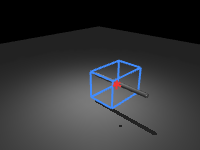

In [6]:
import tempfile
from pathlib import Path

out = Path(tempfile.mkdtemp(prefix="robotdesigner_viz_"))
files = [clip.save(out / "reach.mp4"), clip.save(out / "reach.gif")]
print({f.name: f"{f.stat().st_size / 1e3:.0f} kB" for f in files})
clip.show("gif")

## 5. Several envs, and other cameras

`env_index` takes an int, a list or `"all"`; several envs are tiled and labelled. A camera is a named view (`iso`,
`front`, `side`, `top`), a `CameraSpec`, or a MuJoCo camera.

In [7]:
traj, clip_all = record_rollout(env, 100, policy, env_index="all", every=3, size=(120, 160))
print(clip_all)
clip_all

Clip(35 frames, 246x326, 16.6667 fps, 2.10 s)


Clip(35 frames, 246x326, 16.6667 fps, 2.10 s)

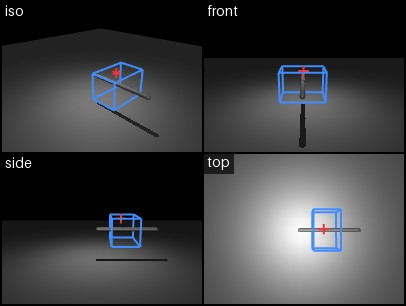

In [8]:
env.reset()
views = [annotate(env.render(0, camera=v, size=(150, 200)), v) for v in VIEWS]
show(tile(views, ncols=2))

## 6. Comparing embodiments

Give every embodiment the **same camera** (`auto_camera` frames the workspaces of all configs at once) and the **same
target** (injected through the reset), then tile the clips side by side. With each embodiment's own camera a short arm
would look as large as a long one. The reach env draws its random numbers in an order that depends on `n`, so the same
seed does not give different embodiments the same target; injecting it does.

The printed closest approach shows how each embodiment did with the same policy and target. A two-joint arm sweeps
a surface, so it cannot reach most 3-D targets.

In [9]:
configs = {f"n={n}  L={L}": make_config(n=n, length=L, num_envs=1, horizon=100) for n, L in [(2, 0.6), (3, 0.9), (5, 1.4)]}
shared = auto_camera(*configs.values())
same_task = TensorDict({"target": torch.tensor([[0.35, 0.10, 0.0]])}, batch_size=[1])

clips = []
for name, cfg in configs.items():
    e = make_env(cfg)
    traj, c = record_rollout(e, 100, make_reach_policy(e), camera=shared, reset_td=same_task, every=3,
                             size=(120, 160), label=False)
    dist = (traj["next", "task", "target_pos"] - traj["next", "task", "ee_pos"]).norm(dim=-1).min().item()
    print(f"{name}: robot_hash={e.robot_hash}  closest approach {dist:.3f} m  reached={bool(traj['next', 'success'].any())}")
    clips.append(c)
    e.close()

tile_clips(clips, labels=list(configs), ncols=3)

n=2  L=0.6: robot_hash=1463e4f571dd  closest approach 0.238 m  reached=False


n=3  L=0.9: robot_hash=aa954a81e250  closest approach 0.043 m  reached=False


n=5  L=1.4: robot_hash=044e5c2d0c91  closest approach 0.333 m  reached=False


Clip(35 frames, 124x488, 16.6667 fps, 2.10 s)

## 7. Your own loop

`record_rollout` wraps `FrameRecorder`, which is a rollout callback. TorchRL calls a callback after every step except
the last (and except the step that stops a rollout early), so the first and last frames are captured by hand.

In [10]:
rec = FrameRecorder(env, env_index=[0, 1], every=3, size=(120, 160))
td = env.reset()
rec.capture(0)                                                    # the initial state
traj = env.rollout(40, policy, callback=rec, auto_reset=False, tensordict=td)
rec.finish(traj.shape[-1])                                        # the final state
rec.clip()

Clip(15 frames, 124x326, 16.6667 fps, 0.90 s)

In [11]:
env.close()          # frees the renderer